# PCA on Iris Dataset:

# Aim:
- Perform dimensionality reduction on the Iris Dataset using Principal Component Analysis(PCA) and visualize the transformed data to analyze feature reduction and class separability

# Importing Libraries and Load the Data:

In [27]:
from sklearn.datasets import load_iris
import pandas as pd
import matplotlib.pyplot as plt

# For Scaling
from sklearn.preprocessing import StandardScaler

# For PCA
from sklearn.decomposition import PCA

In [28]:
# Data Loading:
iris = load_iris()

X = iris.data
y = iris.target

In [29]:
# Creating Dataframe:
df = pd.DataFrame(
    X,
    columns=iris.feature_names
)

df["target"] = y

df.head(5)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


# Understanding the Data:

In [30]:
print(f"Shape of Data: {df.shape}")

Shape of Data: (150, 5)


# Important for PCA: Scaling:

- PCA looks at the amount of variation/spread in the data.
- If one feature has a much larger scale, it could dominate the PCA calculation.
- So we standardize the features to:

```
Mean = 0
Variance = 1
```

In [31]:
scaler = StandardScaler()

X_std = scaler.fit_transform(X)

# Apply PCA:
- We have 4 Features we need 2 principal components:

In [32]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_std)

In [33]:
print(f"Shape of X_pca: {X_pca.shape}")

Shape of X_pca: (150, 2)


# Create PCA Dataframe:

In [36]:
df_pca = pd.DataFrame(
    X_pca,
    columns=["PC1", "PC2"]
)

df_pca.head(5)

,PC1,PC2
0,-2.264703,0.480027
1,-2.080961,-0.674134
2,-2.364229,-0.341908
3,-2.299384,-0.597395
4,-2.389842,0.646835


# Visualize PCA:

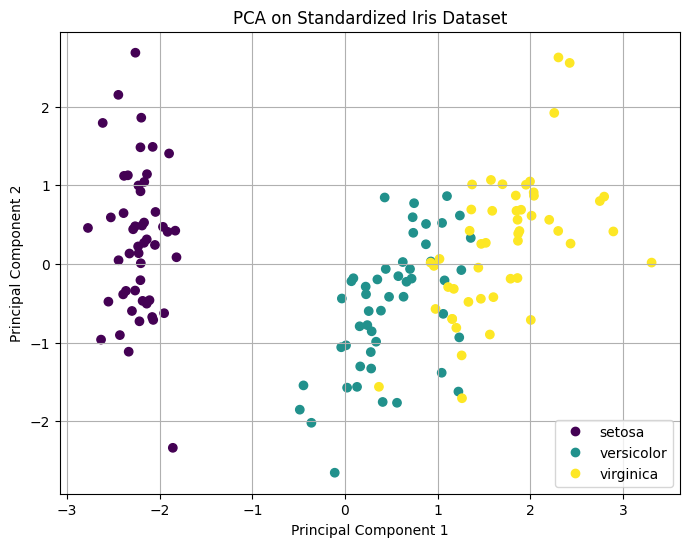

In [37]:
plt.figure(figsize=(8, 6))

scatter = plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=y,
    cmap="viridis"
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.title("PCA on Standardized Iris Dataset")

plt.legend(
    handles=scatter.legend_elements()[0],
    labels=list(iris.target_names)
)

plt.grid(True)
plt.show()

# Explained Variance:
- One of the most important parts of PCA

In [38]:
print(
    "Explained variance ratio:",
    pca.explained_variance_ratio_
)

Explained variance ratio: [0.72962445 0.22850762]


In [39]:
print(
    "Total variance retained:",
    sum(pca.explained_variance_ratio_)
)

Total variance retained: 0.9581320720000164


# Explained Variance Table:

In [60]:
explained_variance = pca.explained_variance_ratio_

# Create table
variance_table = pd.DataFrame({
    "Principal Component": ["PC1", "PC2"],
    "Explained Variance Ratio (%)": explained_variance * 100
})

# Add total
total_variance = explained_variance.sum() * 100

variance_table.loc[len(variance_table)] = [
    "Total",
    total_variance
]

variance_table

,Principal Component,Explained Variance Ratio (%)
0,PC1,72.962445
1,PC2,22.850762
2,Total,95.813207


# Conclusion:
- PCA was successfully applied to the standardized Iris dataset to reduce the four original features to two principal components. The first two principal components retained approximately 95.8% of the total variance, allowing the data to be effectively visualized in two dimensions while preserving most of the class-separating information.